In [ ]:
# practice


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


pd.set_option("display.max_columns", None)

In [ ]:

df_raw = pd.read_csv("house_pricing.csv")
df = df_raw.copy()



In [4]:
df.head()

,size_sqft,bedrooms,location,property_type,distance_to_station_km,house_price
0,800,2.0,Town,Terraced,1.2,160000.0
1,950,2.0,Town,Flat,0.6,185000.0
2,1000,3.0,Town,Terraced,1.5,200000.0
3,1100,3.0,Village,Semi-detached,3.8,210000.0
4,1200,3.0,City,Flat,0.5,260000.0


In [5]:
rows, columns = df.shape
print(rows, columns)

51 6


In [6]:
df.isnull().sum()


size_sqft                 0
bedrooms                  1
location                  1
property_type             0
distance_to_station_km    0
house_price               1
dtype: int64

In [7]:
df.describe()

,size_sqft,bedrooms,distance_to_station_km,house_price
count,51.000000,50.000000,51.000000,50.00000
mean,1421.568627,3.680000,1.645098,295600.00000
std,400.426635,0.843704,1.422577,69683.24836
min,-250.000000,2.000000,-1.000000,160000.00000
25%,1190.000000,3.000000,0.600000,237500.00000
50%,1460.000000,4.000000,1.000000,297500.00000
75%,1690.000000,4.000000,3.250000,350000.00000
max,2100.000000,5.000000,4.500000,425000.00000


In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df["size_sqft"].min()

np.int64(-250)

In [10]:
df["distance_to_station_km"].min()

np.float64(-1.0)

In [11]:
df[df["size_sqft"] < 0]

,size_sqft,bedrooms,location,property_type,distance_to_station_km,house_price
30,-250,5.0,Town,Detached,1.0,395000.0


In [12]:
df[df["distance_to_station_km"] < 0]

,size_sqft,bedrooms,location,property_type,distance_to_station_km,house_price
18,1400,4.0,Town,Terraced,-1.0,280000.0


In [13]:
df.isnull().sum()

size_sqft                 0
bedrooms                  1
location                  1
property_type             0
distance_to_station_km    0
house_price               1
dtype: int64

In [14]:
df.describe()


,size_sqft,bedrooms,distance_to_station_km,house_price
count,51.000000,50.000000,51.000000,50.00000
mean,1421.568627,3.680000,1.645098,295600.00000
std,400.426635,0.843704,1.422577,69683.24836
min,-250.000000,2.000000,-1.000000,160000.00000
25%,1190.000000,3.000000,0.600000,237500.00000
50%,1460.000000,4.000000,1.000000,297500.00000
75%,1690.000000,4.000000,3.250000,350000.00000
max,2100.000000,5.000000,4.500000,425000.00000


In [15]:
df.describe(include="all")

,size_sqft,bedrooms,location,property_type,distance_to_station_km,house_price
count,51.000000,50.000000,50,51,51.000000,50.00000
unique,NaN,NaN,3,4,NaN,NaN
top,NaN,NaN,City,Semi-detached,NaN,NaN
freq,NaN,NaN,19,16,NaN,NaN
mean,1421.568627,3.680000,NaN,NaN,1.645098,295600.00000
std,400.426635,0.843704,NaN,NaN,1.422577,69683.24836
min,-250.000000,2.000000,NaN,NaN,-1.000000,160000.00000
25%,1190.000000,3.000000,NaN,NaN,0.600000,237500.00000
50%,1460.000000,4.000000,NaN,NaN,1.000000,297500.00000
75%,1690.000000,4.000000,NaN,NaN,3.250000,350000.00000


In [16]:
df_clean = df.copy()

In [17]:
df_clean = df_clean.drop_duplicates()

In [18]:
print(df.shape)
print(df_clean.shape)
print(df_clean.duplicated().sum())

(51, 6)
(50, 6)
0


In [19]:
df.describe()

,size_sqft,bedrooms,distance_to_station_km,house_price
count,51.000000,50.000000,51.000000,50.00000
mean,1421.568627,3.680000,1.645098,295600.00000
std,400.426635,0.843704,1.422577,69683.24836
min,-250.000000,2.000000,-1.000000,160000.00000
25%,1190.000000,3.000000,0.600000,237500.00000
50%,1460.000000,4.000000,1.000000,297500.00000
75%,1690.000000,4.000000,3.250000,350000.00000
max,2100.000000,5.000000,4.500000,425000.00000


In [20]:
print("Invalid house sizes:")
print(df[df["size_sqft"] <= 0])

print("\nInvalid station distances:")
print(df[df["distance_to_station_km"] < 0])

Invalid house sizes:
    size_sqft  bedrooms location property_type  distance_to_station_km  \
30       -250       5.0     Town      Detached                     1.0   

    house_price  
30     395000.0  

Invalid station distances:
    size_sqft  bedrooms location property_type  distance_to_station_km  \
18       1400       4.0     Town      Terraced                    -1.0   

    house_price  
18     280000.0  


In [21]:
print(df.loc[[18, 30]])

    size_sqft  bedrooms location property_type  distance_to_station_km  \
18       1400       4.0     Town      Terraced                    -1.0   
30       -250       5.0     Town      Detached                     1.0   

    house_price  
18     280000.0  
30     395000.0  


In [22]:
invalid_counts = pd.Series({
    "size_sqft": (df["size_sqft"] <= 0).sum(), "distance_to_station_km": ( df["distance_to_station_km"] < 0).sum(),
    "house_price": (df["house_price"] <= 0).sum()
})

print(invalid_counts)

size_sqft                 1
distance_to_station_km    1
house_price               0
dtype: int64


In [23]:
import numpy as np

df.loc[df["size_sqft"] <= 0, "size_sqft"] = np.nan

df.loc[
    df["distance_to_station_km"] < 0,
    "distance_to_station_km"
] = np.nan

In [24]:
print(df.loc[[18, 30]])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

    size_sqft  bedrooms location property_type  distance_to_station_km  \
18     1400.0       4.0     Town      Terraced                     NaN   
30        NaN       5.0     Town      Detached                     1.0   

    house_price  
18     280000.0  
30     395000.0  

Missing values after cleaning:
size_sqft                 1
bedrooms                  1
location                  1
property_type             0
distance_to_station_km    1
house_price               1
dtype: int64


In [25]:
missing_rows = df[df.isnull().any(axis=1)]

print(missing_rows)

    size_sqft  bedrooms location  property_type  distance_to_station_km  \
5      1250.0       NaN     Town  Semi-detached                     1.0   
12     1800.0       5.0      NaN       Detached                     3.5   
18     1400.0       4.0     Town       Terraced                     NaN   
22     1150.0       3.0     Town           Flat                     1.0   
30        NaN       5.0     Town       Detached                     1.0   

    house_price  
5      245000.0  
12     360000.0  
18     280000.0  
22          NaN  
30     395000.0  


In [26]:
missing_rows = df[df.isnull().any(axis=1)]

print(missing_rows)

    size_sqft  bedrooms location  property_type  distance_to_station_km  \
5      1250.0       NaN     Town  Semi-detached                     1.0   
12     1800.0       5.0      NaN       Detached                     3.5   
18     1400.0       4.0     Town       Terraced                     NaN   
22     1150.0       3.0     Town           Flat                     1.0   
30        NaN       5.0     Town       Detached                     1.0   

    house_price  
5      245000.0  
12     360000.0  
18     280000.0  
22          NaN  
30     395000.0  


In [27]:
print(df["bedrooms"].value_counts().sort_index())



bedrooms
2.0     4
3.0    16
4.0    22
5.0     8
Name: count, dtype: int64


In [28]:
print(df["bedrooms"].median())
print(df["bedrooms"].mode())

4.0
0    4.0
Name: bedrooms, dtype: float64


In [29]:
print("Median:", df["bedrooms"].median())
print("Mode:", df["bedrooms"].mode().tolist())

Median: 4.0
Mode: [4.0]


In [30]:
df["bedrooms"] = df["bedrooms"].fillna(
    df["bedrooms"].median()
)

In [31]:
print(df.loc[5])
print("Missing bedroom values:", df["bedrooms"].isnull().sum())

size_sqft                        1250.0
bedrooms                            4.0
location                           Town
property_type             Semi-detached
distance_to_station_km              1.0
house_price                    245000.0
Name: 5, dtype: object
Missing bedroom values: 0


In [32]:
print(df["location"].value_counts())
print("Missing locations:", df["location"].isnull().sum())

location
City       19
Town       18
Village    13
Name: count, dtype: int64
Missing locations: 1


In [33]:
print(df.loc[22])

size_sqft                 1150.0
bedrooms                     3.0
location                    Town
property_type               Flat
distance_to_station_km       1.0
house_price                  NaN
Name: 22, dtype: object


In [34]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nInvalid house sizes:", (df["size_sqft"] <= 0).sum())

print(
    "Invalid station distances:",
    (df["distance_to_station_km"] < 0).sum()
)

print(
    "Invalid house prices:",
    (df["house_price"] <= 0).sum()
)

Dataset shape: (51, 6)

Missing values:
size_sqft                 1
bedrooms                  0
location                  1
property_type             0
distance_to_station_km    1
house_price               1
dtype: int64

Duplicate rows: 1

Invalid house sizes: 0
Invalid station distances: 0
Invalid house prices: 0


In [35]:
duplicates = df[df.duplicated(keep=False)]

print(duplicates)

    size_sqft  bedrooms location  property_type  distance_to_station_km  \
8      1500.0       4.0     City  Semi-detached                     0.7   
50     1500.0       4.0     City  Semi-detached                     0.7   

    house_price  
8      320000.0  
50     320000.0  


In [36]:
df = df.drop_duplicates().copy()

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (50, 6)
Duplicate rows: 0


In [37]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nInvalid house sizes:", (df["size_sqft"] <= 0).sum())

print(
    "Invalid station distances:",
    (df["distance_to_station_km"] < 0).sum()
)

print(
    "Invalid house prices:",
    (df["house_price"] <= 0).sum()
)

Dataset shape: (50, 6)

Missing values:
size_sqft                 1
bedrooms                  0
location                  1
property_type             0
distance_to_station_km    1
house_price               1
dtype: int64

Duplicate rows: 0

Invalid house sizes: 0
Invalid station distances: 0
Invalid house prices: 0


In [38]:
print(df.describe())

         size_sqft   bedrooms  distance_to_station_km    house_price
count    49.000000  50.000000               49.000000      49.000000
mean   1454.081633   3.680000                1.718367  295102.040816
std     328.030222   0.843704                1.392192   70315.433612
min     800.000000   2.000000                0.300000  160000.000000
25%    1200.000000   3.000000                0.600000  235000.000000
50%    1460.000000   4.000000                1.100000  295000.000000
75%    1700.000000   4.000000                3.300000  350000.000000
max    2100.000000   5.000000                4.500000  425000.000000


In [39]:
print(df[["size_sqft", "house_price"]].corr())

             size_sqft  house_price
size_sqft     1.000000     0.971774
house_price   0.971774     1.000000


<Axes: title={'center': 'House Size vs House Price'}, xlabel='size_sqft', ylabel='house_price'>

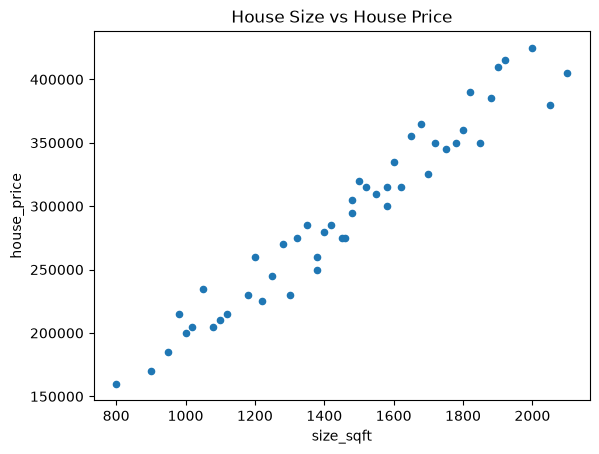

In [40]:
df.plot.scatter(
    x="size_sqft",
    y="house_price",
    title="House Size vs House Price"
)

In [41]:
correlation = df["size_sqft"].corr(df["house_price"])

print(f"Correlation: {correlation:.3f}")

Correlation: 0.972


In [42]:
valid_data = df[["size_sqft", "house_price"]].dropna()

m, b = np.polyfit(
    valid_data["size_sqft"],
    valid_data["house_price"],
    1
)

print(f"Slope (m): {m:.2f}")
print(f"Intercept (b): {b:.2f}")

Slope (m): 205.67
Intercept (b): -7349.11


In [43]:
size = 1500

predicted_price = m * size + b

print(f"Predicted price: {predicted_price:.2f}")

Predicted price: 301162.10


In [44]:
valid_data = df[["size_sqft", "house_price"]].dropna().copy()

valid_data["predicted_price"] = (
    m * valid_data["size_sqft"] + b
)

valid_data["error"] = (
    valid_data["house_price"] - valid_data["predicted_price"]
)

print(valid_data.head())

   size_sqft  house_price  predicted_price         error
0      800.0     160000.0    157190.202984   2809.797016
1      950.0     185000.0    188041.324073  -3041.324073
2     1000.0     200000.0    198325.031103   1674.968897
3     1100.0     210000.0    218892.445162  -8892.445162
4     1200.0     260000.0    239459.859221  20540.140779


In [45]:
mae = valid_data["error"].abs().mean()

print(f"Mean Absolute Error: {mae:.2f}")

Mean Absolute Error: 13399.88


In [46]:
rmse = np.sqrt((valid_data["error"] ** 2).mean())

print(f"Root Mean Squared Error: {rmse:.2f}")

Root Mean Squared Error: 16228.55


In [47]:
model_data = df[["size_sqft", "house_price"]].dropna().copy()

X = model_data[["size_sqft"]]
y = model_data["house_price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

y.head()

Features shape: (48, 1)
Target shape: (48,)


0    160000.0
1    185000.0
2    200000.0
3    210000.0
4    260000.0
Name: house_price, dtype: float64

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Test targets:", y_test.shape)

Training features: (38, 1)
Test features: (10, 1)
Training targets: (38,)
Test targets: (10,)


In [49]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 206.56972431903887
Intercept: -8668.052458899561


In [50]:
# Predict prices for the test houses
y_pred = model.predict(X_test)

# Compare predicted prices with actual prices
results = X_test.copy()
results["actual_price"] = y_test
results["predicted_price"] = y_pred
results["error"] = results["actual_price"] - results["predicted_price"]

print(results.round(2))

    size_sqft  actual_price  predicted_price     error
28     1380.0      260000.0        276398.17 -16398.17
42     1480.0      305000.0        297055.14   7944.86
27     1720.0      350000.0        346631.87   3368.13
45     1380.0      250000.0        276398.17 -26398.17
25     1480.0      295000.0        297055.14  -2055.14
39     1620.0      315000.0        325974.90 -10974.90
12     1800.0      360000.0        363157.45  -3157.45
19     1600.0      335000.0        321843.51  13156.49
4      1200.0      260000.0        239215.62  20784.38
26     1280.0      270000.0        255741.19  14258.81


In [51]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(f"Test MAE: {mae:.2f}")
print(f"Test RMSE: {rmse:.2f}")

Test MAE: 11849.65
Test RMSE: 14082.85


In [52]:
# Calculate the average price using training data only
baseline_price = y_train.mean()

# Predict that same price for every test house
baseline_predictions = [baseline_price] * len(y_test)

print(f"Baseline price: {baseline_price:.2f}")
print(f"Number of predictions: {len(baseline_predictions)}")

Baseline price: 291184.21
Number of predictions: 10
